In [2]:
# Day 3: Causal Exploratory Data Analysis
# Step 1: Upload and load engineered features

import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("engineered_features.csv")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Saving engineered_features.csv to engineered_features.csv
Dataset loaded successfully!

Dataset Shape:
(25249, 31)

First 5 Rows:


,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,avg_competitor_price,price_gap,price_gap_pct,discount_amount,revenue_per_unit,avg_competitor_price_missing,price_gap_missing,price_gap_pct_missing,discount_amount_missing,revenue_per_unit_missing
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,37.31,-2.01,-5.387296,1.68,35.300000,0,0,0,0,0
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.31,0.41,1.098901,0.10,37.723333,0,0,0,0,0
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,37.31,-0.83,-2.224605,0.40,36.480000,0,0,0,0,0
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.31,0.19,0.509247,-0.02,37.500000,0,0,0,0,0
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.23,-0.08,-0.135067,-0.14,59.150000,0,0,0,0,0


In [3]:
#Step 2 - Identify Treatment Groups

print("Pricing Treatment Groups:")
print(df["pricing_treatment_flag"].value_counts())

print("\nTreatment Phases:")
print(df["treatment_phase"].value_counts())

print("\nTreatment Group Percentages:")
print(
    df["pricing_treatment_flag"]
    .value_counts(normalize=True) * 100
)

Pricing Treatment Groups:
pricing_treatment_flag
0    23460
1     1789
Name: count, dtype: int64

Treatment Phases:
treatment_phase
Pre-treatment     19055
Control-period     4405
Treatment          1789
Name: count, dtype: int64

Treatment Group Percentages:
pricing_treatment_flag
0    92.914571
1     7.085429
Name: proportion, dtype: float64


In [4]:
#Step 3 - Compare Average Revenue

revenue_comparison = (
    df.groupby("pricing_treatment_flag")["revenue"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
)

print("Revenue Comparison: Treatment vs Control")
display(revenue_comparison)

Revenue Comparison: Treatment vs Control


,count,mean,median,sum
pricing_treatment_flag,,,,
0,23460,124.38,90.87,2917930.74
1,1789,126.60,95.27,226494.01


In [5]:
# Step 4 - Revenue by Treatment Phase

phase_comparison = (
    df.groupby("treatment_phase")["revenue"]
    .agg(["count", "mean", "median", "sum"])
    .round(2)
)

print("Revenue Comparison by Treatment Phase:")
display(phase_comparison)

Revenue Comparison by Treatment Phase:


,count,mean,median,sum
treatment_phase,,,,
Control-period,4405,123.65,89.74,544660.55
Pre-treatment,19055,124.55,91.31,2373270.19
Treatment,1789,126.60,95.27,226494.01


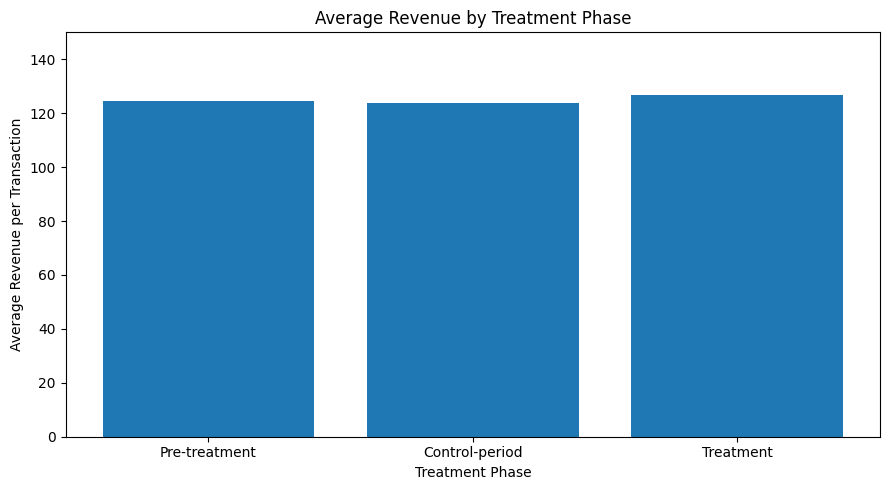

In [6]:
# Step 5 - Revenue Comparison Bar Chart

import matplotlib.pyplot as plt

phase_order = [
    "Pre-treatment",
    "Control-period",
    "Treatment"
]

avg_revenue = (
    df.groupby("treatment_phase")["revenue"]
    .mean()
    .reindex(phase_order)
)

plt.figure(figsize=(9, 5))

plt.bar(avg_revenue.index, avg_revenue.values)

plt.title("Average Revenue by Treatment Phase")
plt.xlabel("Treatment Phase")
plt.ylabel("Average Revenue per Transaction")

plt.ylim(0, 150)
plt.tight_layout()
plt.show()

In [7]:
# Step 6 - Revenue Comparison by Region

region_comparison = (
    df.groupby(["region_name", "pricing_treatment_flag"])["revenue"]
    .agg(["count", "mean"])
    .round(2)
    .reset_index()
)

print("Revenue Comparison by Region:")
display(region_comparison)

Revenue Comparison by Region:


,region_name,pricing_treatment_flag,count,mean
0,Central,0,3192,127.75
1,Coastal,0,2942,120.67
2,East Metro,0,3071,124.52
3,Hill,0,2631,118.94
4,Lakeside,0,2818,118.79
5,North Metro,0,2769,128.83
6,North Metro,1,920,131.58
7,South Metro,0,3356,125.09
8,West Metro,0,2667,130.09
9,West Metro,1,868,121.33


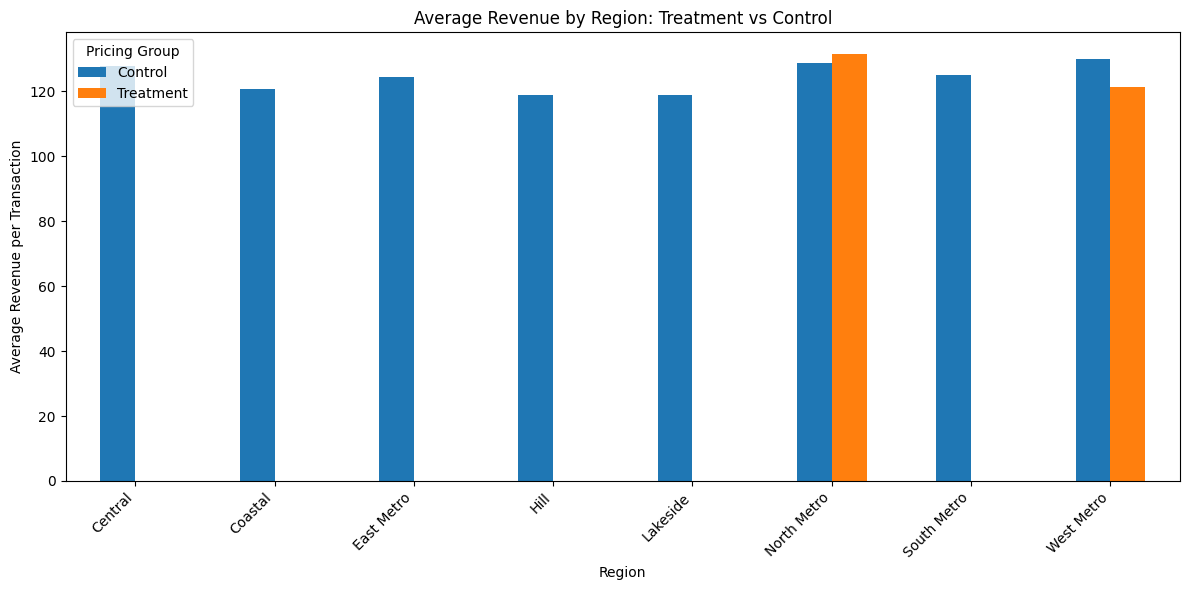

In [8]:
# Step 7 - Regional Revenue Comparison

import matplotlib.pyplot as plt

region_pivot = df.pivot_table(
    index="region_name",
    columns="pricing_treatment_flag",
    values="revenue",
    aggfunc="mean"
)

region_pivot = region_pivot.rename(
    columns={0: "Control", 1: "Treatment"}
)

region_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Revenue by Region: Treatment vs Control")
plt.xlabel("Region")
plt.ylabel("Average Revenue per Transaction")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Pricing Group")
plt.tight_layout()
plt.show()

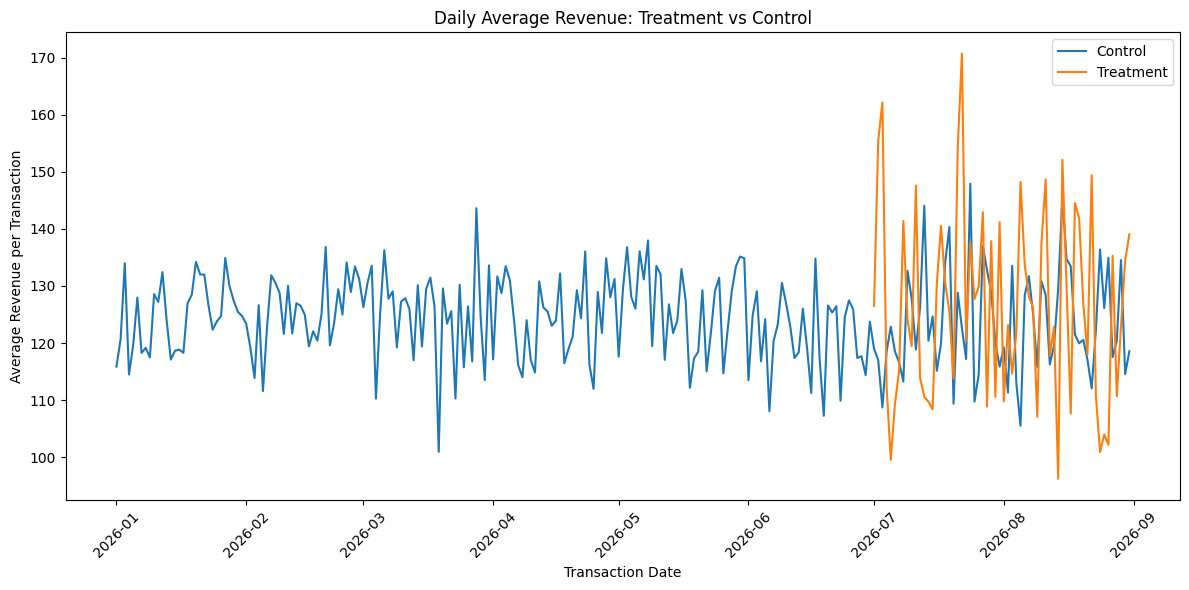

In [9]:
# Step 8 - Daily Revenue Trends

import pandas as pd
import matplotlib.pyplot as plt

# Convert transaction date to datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Calculate daily average revenue by group
daily_revenue = (
    df.groupby(
        ["transaction_date", "pricing_treatment_flag"]
    )["revenue"]
    .mean()
    .unstack()
)

# Rename groups
daily_revenue = daily_revenue.rename(
    columns={0: "Control", 1: "Treatment"}
)

# Plot daily revenue trends
plt.figure(figsize=(12, 6))

for group in daily_revenue.columns:
    plt.plot(
        daily_revenue.index,
        daily_revenue[group],
        label=group
    )

plt.title("Daily Average Revenue: Treatment vs Control")
plt.xlabel("Transaction Date")
plt.ylabel("Average Revenue per Transaction")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
#Step 9 - Revenue Comparison by Product

product_comparison = (
    df.groupby(
        ["product_name", "pricing_treatment_flag"]
    )["revenue"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

print("Revenue Comparison by Product:")
display(product_comparison)

Revenue Comparison by Product:


,product_name,pricing_treatment_flag,count,mean,median
0,Beauty Combo,0,3941,109.86,76.92
1,Beauty Combo,1,301,114.66,80.07
2,Everyday Essentials,0,5194,51.64,35.84
3,Everyday Essentials,1,409,52.57,37.37
4,Fitness Bundle,0,3745,132.31,92.11
5,Fitness Bundle,1,281,137.79,95.94
6,Home Care Pack,0,4343,80.18,56.37
7,Home Care Pack,1,328,82.40,58.63
8,Premium Gadget,0,2883,267.81,184.16
9,Premium Gadget,1,212,262.45,192.06


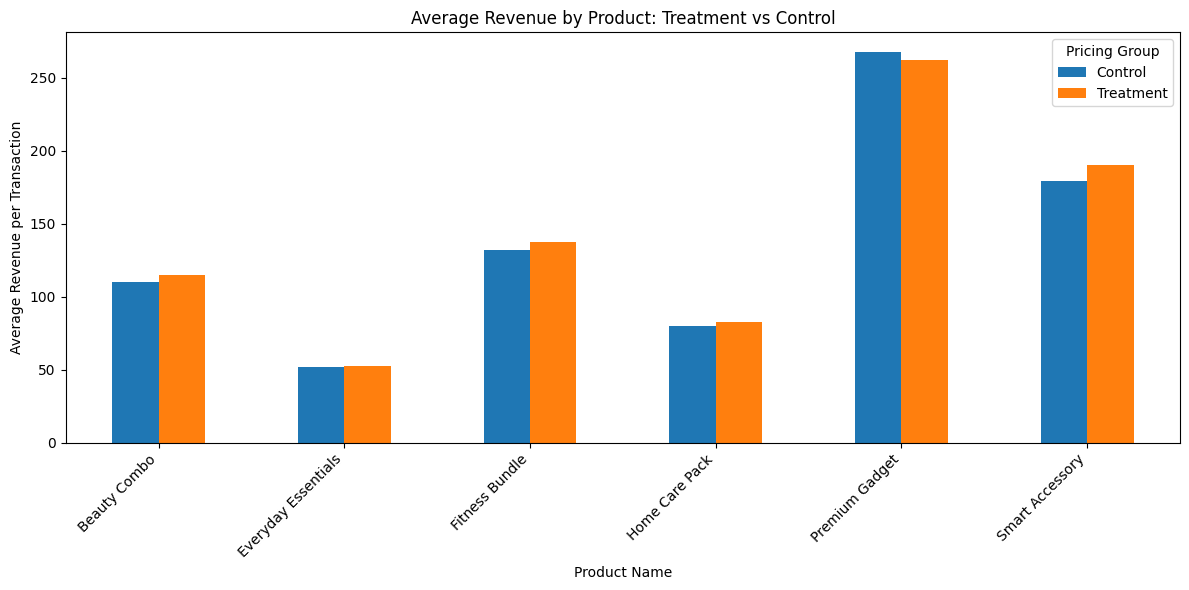

In [11]:
#Step 10 - Product-wise Revenue Comparison

import matplotlib.pyplot as plt

product_pivot = df.pivot_table(
    index="product_name",
    columns="pricing_treatment_flag",
    values="revenue",
    aggfunc="mean"
)

product_pivot = product_pivot.rename(
    columns={0: "Control", 1: "Treatment"}
)

product_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Revenue by Product: Treatment vs Control")
plt.xlabel("Product Name")
plt.ylabel("Average Revenue per Transaction")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Pricing Group")
plt.tight_layout()
plt.show()

In [12]:
# Step 11 - Pricing and Discount Analysis

pricing_comparison = (
    df.groupby("pricing_treatment_flag")[
        [
            "selling_price",
            "discount_pct",
            "avg_competitor_price",
            "price_gap"
        ]
    ]
    .mean()
    .round(2)
)

print("Pricing and Discount Comparison:")
display(pricing_comparison)

Pricing and Discount Comparison:


,selling_price,discount_pct,avg_competitor_price,price_gap
pricing_treatment_flag,,,,
0,82.92,1.5,83.78,-0.86
1,87.30,1.4,87.74,-0.45


In [13]:
# Step 12 - Customer Segment Revenue Analysis

segment_comparison = (
    df.groupby(
        ["customer_segment", "pricing_treatment_flag"]
    )["revenue"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

print("Revenue Comparison by Customer Segment:")
display(segment_comparison)

Revenue Comparison by Customer Segment:


,customer_segment,pricing_treatment_flag,count,mean,median
0,New,0,6543,123.07,90.74
1,New,1,486,124.02,95.64
2,Premium,0,3251,127.11,91.48
3,Premium,1,246,130.27,96.50
4,Returning,0,13666,124.36,90.82
5,Returning,1,1057,126.94,94.90


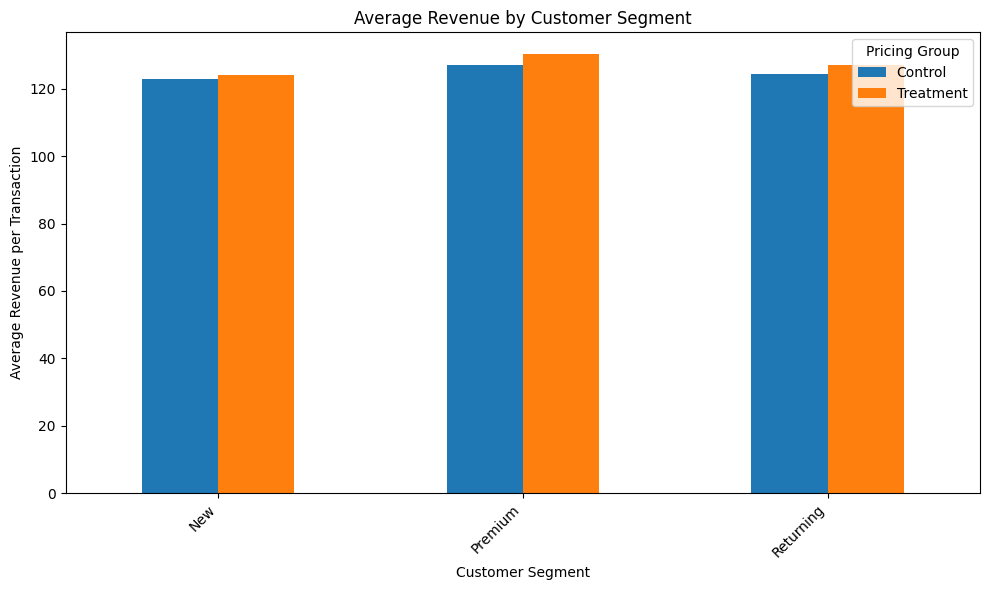

In [14]:
#Step 13 - Customer Segment Revenue Visualization

import matplotlib.pyplot as plt

segment_pivot = df.pivot_table(
    index="customer_segment",
    columns="pricing_treatment_flag",
    values="revenue",
    aggfunc="mean"
)

segment_pivot = segment_pivot.rename(
    columns={0: "Control", 1: "Treatment"}
)

segment_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Revenue per Transaction")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Pricing Group")
plt.tight_layout()
plt.show()

In [15]:
#Step 14 - Final Causal EDA Summary

print("=" * 50)
print("DAY 3: CAUSAL EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 50)

print("\n1. Dataset Overview")
print("Total Transactions:", len(df))
print("Total Features:", df.shape[1])

print("\n2. Treatment Distribution")
print(df["pricing_treatment_flag"].value_counts())

print("\n3. Average Revenue Comparison")
print(
    df.groupby("pricing_treatment_flag")["revenue"]
    .mean()
    .round(2)
)

print("\n4. Revenue by Treatment Phase")
print(
    df.groupby("treatment_phase")["revenue"]
    .mean()
    .round(2)
)

print("\n5. Regional Coverage")
print("Total Regions:", df["region_name"].nunique())

print("\n6. Product Coverage")
print("Total Products:", df["product_name"].nunique())

print("\n7. Customer Segment Coverage")
print("Total Segments:", df["customer_segment"].nunique())

print("\n8. Key Observation")
print(
    "Treatment and control groups show differences "
    "in average revenue. These are descriptive "
    "associations, not confirmed causal effects."
)

print("\nDay 3 Causal EDA Summary Generated Successfully!")

DAY 3: CAUSAL EXPLORATORY DATA ANALYSIS SUMMARY

1. Dataset Overview
Total Transactions: 25249
Total Features: 31

2. Treatment Distribution
pricing_treatment_flag
0    23460
1     1789
Name: count, dtype: int64

3. Average Revenue Comparison
pricing_treatment_flag
0    124.38
1    126.60
Name: revenue, dtype: float64

4. Revenue by Treatment Phase
treatment_phase
Control-period    123.65
Pre-treatment     124.55
Treatment         126.60
Name: revenue, dtype: float64

5. Regional Coverage
Total Regions: 8

6. Product Coverage
Total Products: 6

7. Customer Segment Coverage
Total Segments: 3

8. Key Observation
Treatment and control groups show differences in average revenue. These are descriptive associations, not confirmed causal effects.

Day 3 Causal EDA Summary Generated Successfully!
